# FY2025–26 renewable-profile comparison

This notebook compares the archived previous model input with the corrected nine-balancing-area profile set now active in the model. Both datasets are hourly capacity factors, not realised generation. The new table was shifted **five hours later**, with a fiscal-year boundary wrap, to match the model's hourly convention.

Scope: 1 April 2025 00:00 to 31 March 2026 23:00; nine balancing areas; wind and solar.

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_rows', 30)
pd.set_option('display.float_format', '{:,.4f}'.format)

# Run from either the repository root or the notebooks directory.
ROOT = Path.cwd().resolve()
if not (ROOT / 'data').exists() and (ROOT.parent / 'data').exists():
    ROOT = ROOT.parent
if not (ROOT / 'data').exists():
    raise FileNotFoundError('Run this notebook from the repository root or notebooks directory.')

MODEL_INPUT = ROOT / 'data' / 'model_inputs' / 'renewable_profiles_before_external_FY2025_26.csv'
EXTERNAL_INPUT = ROOT / 'data' / 'model_inputs' / 'renewable_profiles.csv'
GENERATORS = ROOT / 'model' / 'generators.csv'

AREAS = [
    'chennai_north', 'chennai_south', 'coimbatore', 'erode', 'madurai',
    'tirunelveli', 'trichy', 'vellore', 'villupuram',
]
TECHNOLOGIES = ['wind', 'solar']
AREA_LABELS = [area.replace('_', ' ').title() for area in AREAS]


In [2]:
model = pd.read_csv(MODEL_INPUT, parse_dates=['snapshot']).set_index('snapshot')
external = pd.read_csv(EXTERNAL_INPUT, parse_dates=['snapshot']).set_index('snapshot')
profile_columns = [f'{area}_{technology}' for area in AREAS for technology in TECHNOLOGIES]

expected_hours = pd.date_range('2025-04-01 00:00:00', '2026-03-31 23:00:00', freq='h')
assert model.index.equals(expected_hours), 'Previous model snapshots are not the expected fiscal year.'
assert external.index.equals(expected_hours), 'New model snapshots are not the expected fiscal year.'
assert set(profile_columns).issubset(model.columns)
assert set(profile_columns).issubset(external.columns)

model = model[profile_columns].astype(float)
external = external[profile_columns].astype(float)
assert not model.isna().any().any() and not external.isna().any().any()
assert ((model >= 0) & (model <= 1)).all().all()
assert ((external >= 0) & (external <= 1)).all().all()

difference = external - model  # positive means higher availability in the new active profile
display(Markdown(
    f'Loaded **{len(model):,} hourly snapshots**, **{len(profile_columns)} profiles**, '
    f'from **{model.index.min():%d %b %Y}** through **{model.index.max():%d %b %Y}**.'
))


Loaded **8,760 hourly snapshots**, **18 profiles**, from **01 Apr 2025** through **31 Mar 2026**.

## 1. Exact annual comparison by area and technology

`Mean CF difference` is new active minus previous model capacity factor. MAE and RMSE retain hourly detail; correlation describes matching hourly shape after the five-hour correction.

In [3]:
summary_rows = []
for area in AREAS:
    for technology in TECHNOLOGIES:
        column = f'{area}_{technology}'
        active_mean = model[column].mean()
        external_mean = external[column].mean()
        delta = difference[column]
        summary_rows.append({
            'Area': area.replace('_', ' ').title(),
            'Technology': technology.title(),
            'Previous model mean CF': active_mean,
            'New active mean CF': external_mean,
            'Mean CF difference': delta.mean(),
            'Relative change (%)': 100 * delta.mean() / active_mean,
            'Hourly MAE': delta.abs().mean(),
            'Hourly RMSE': np.sqrt((delta ** 2).mean()),
            'Hourly correlation': model[column].corr(external[column]),
            'Maximum absolute difference': delta.abs().max(),
        })

annual_summary = pd.DataFrame(summary_rows).set_index(['Technology', 'Area']).sort_index()
display(annual_summary.style.format({
    'Previous model mean CF': '{:.3f}', 'New active mean CF': '{:.3f}',
    'Mean CF difference': '{:+.3f}', 'Relative change (%)': '{:+.1f}',
    'Hourly MAE': '{:.3f}', 'Hourly RMSE': '{:.3f}',
    'Hourly correlation': '{:.3f}', 'Maximum absolute difference': '{:.3f}',
}).background_gradient(subset=['Mean CF difference'], cmap='RdYlGn'))


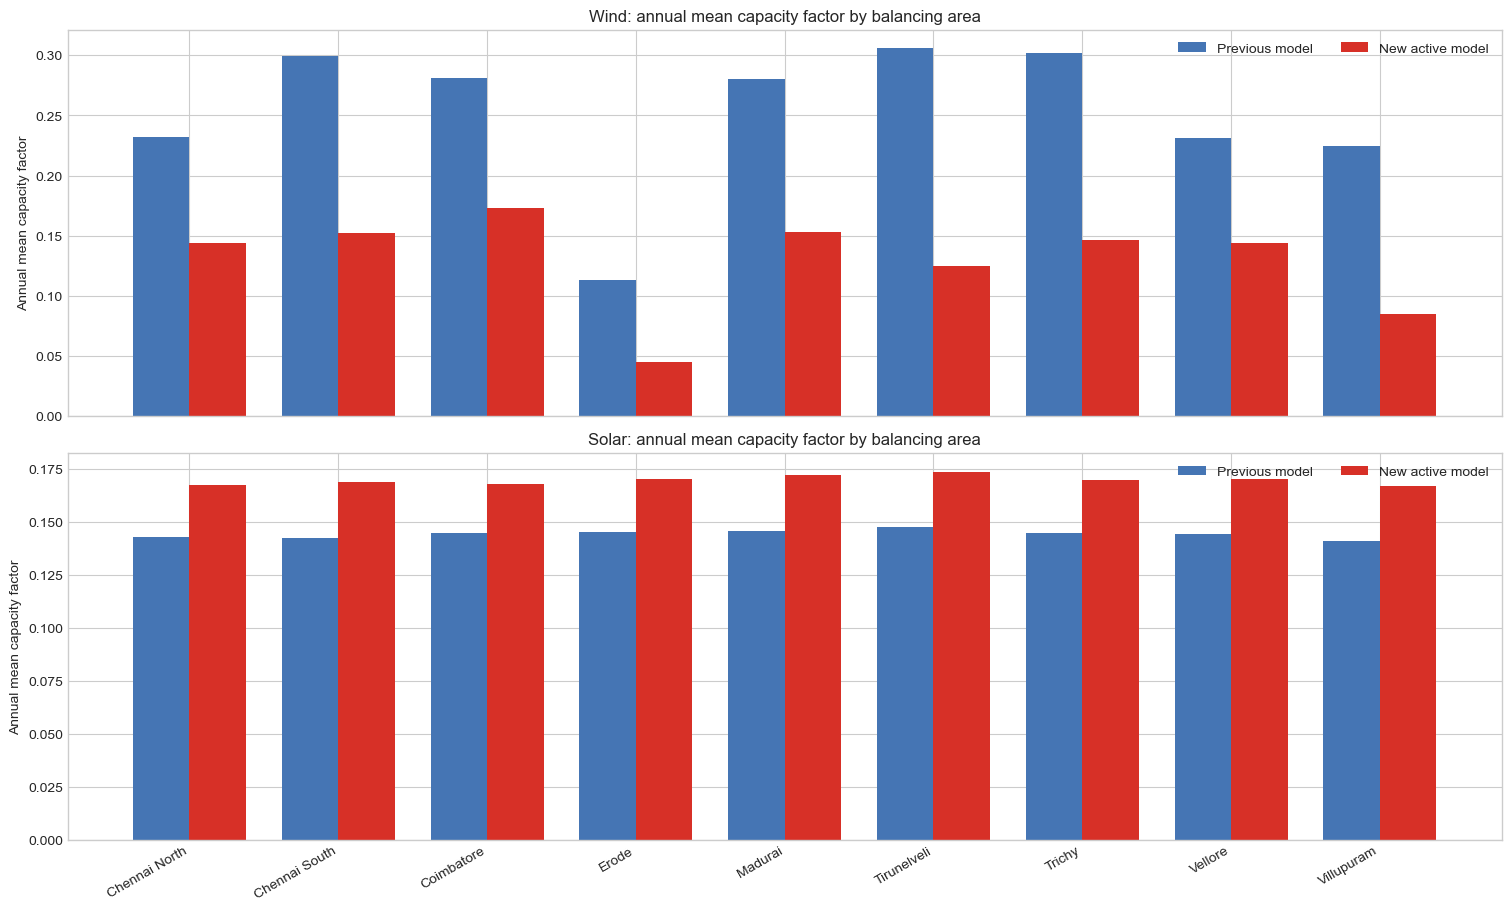

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(15, 9), sharex=True, constrained_layout=True)
x = np.arange(len(AREAS))
width = 0.38
for axis, technology in zip(axes, TECHNOLOGIES):
    active_means = [model[f'{area}_{technology}'].mean() for area in AREAS]
    external_means = [external[f'{area}_{technology}'].mean() for area in AREAS]
    axis.bar(x - width / 2, active_means, width, label='Previous model', color='#4575b4')
    axis.bar(x + width / 2, external_means, width, label='New active model', color='#d73027')
    axis.set_ylabel('Annual mean capacity factor')
    axis.set_title(f'{technology.title()}: annual mean capacity factor by balancing area')
    axis.legend(ncols=2, loc='upper right')
    axis.set_ylim(bottom=0)
axes[-1].set_xticks(x, AREA_LABELS, rotation=30, ha='right')
plt.show()


## 2. Seasonal pattern: monthly mean differences across every area

Each cell is the mean hourly CF difference for that calendar month. This makes persistent seasonal bias visible without obscuring it with daily weather variation.

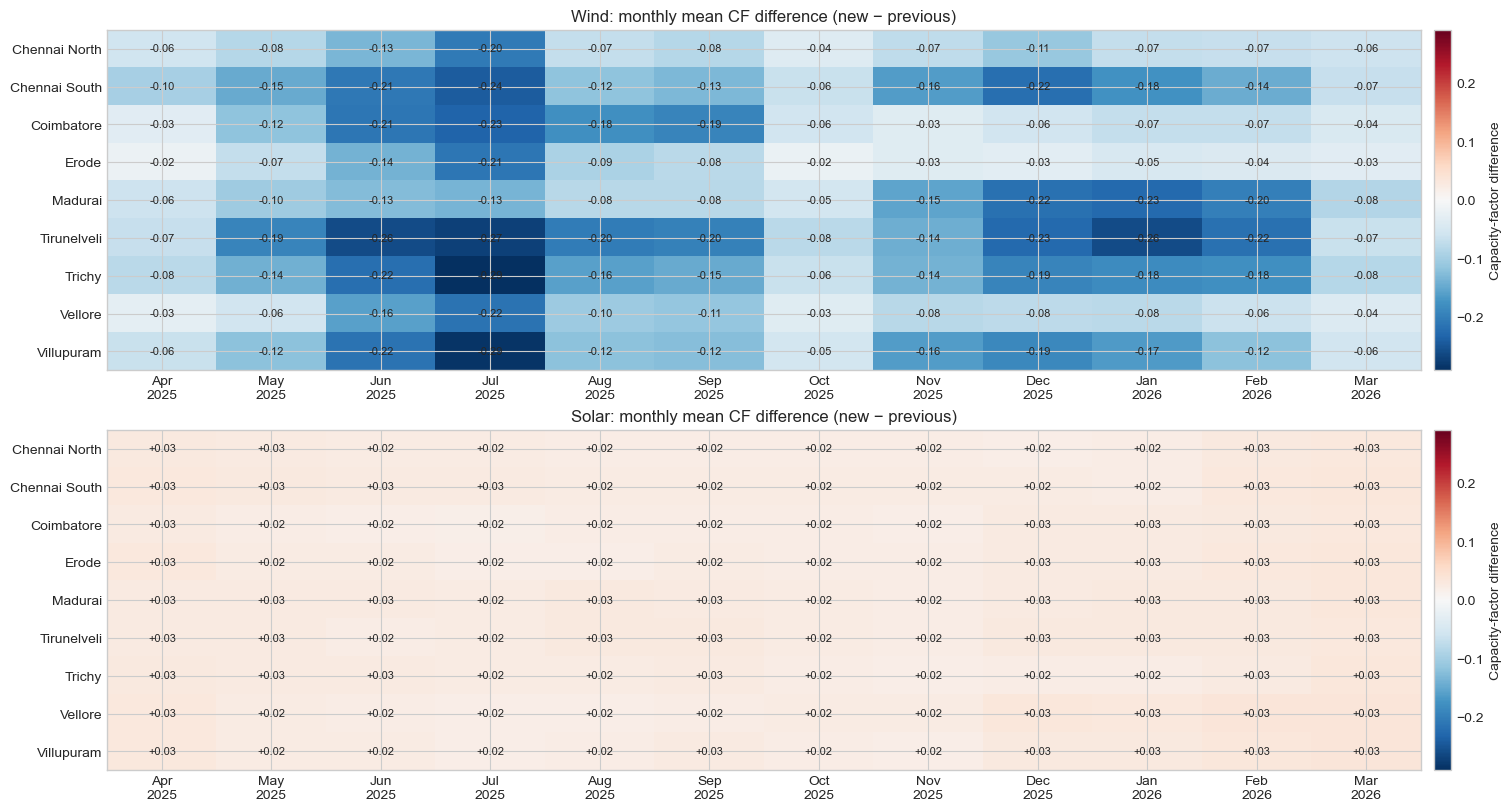

In [5]:
monthly = difference.resample('MS').mean()
month_labels = [timestamp.strftime('%b\n%Y') for timestamp in monthly.index]
limit = monthly.abs().to_numpy().max()
fig, axes = plt.subplots(2, 1, figsize=(15, 8), constrained_layout=True)
for axis, technology in zip(axes, TECHNOLOGIES):
    matrix = monthly[[f'{area}_{technology}' for area in AREAS]].T.to_numpy()
    image = axis.imshow(matrix, aspect='auto', cmap='RdBu_r', vmin=-limit, vmax=limit)
    axis.set_yticks(np.arange(len(AREAS)), AREA_LABELS)
    axis.set_xticks(np.arange(len(monthly)), month_labels)
    axis.set_title(f'{technology.title()}: monthly mean CF difference (new − previous)')
    for row in range(matrix.shape[0]):
        for column in range(matrix.shape[1]):
            axis.text(column, row, f'{matrix[row, column]:+.02f}', ha='center', va='center', fontsize=8)
    colorbar = fig.colorbar(image, ax=axis, pad=0.01)
    colorbar.set_label('Capacity-factor difference')
plt.show()


## 3. Whole-year daily detail across all nine areas

Rows are balancing areas and columns are every day of FY2025–26. These heatmaps preserve the full-year chronology and show whether differences are seasonal, event-driven, or area-specific.

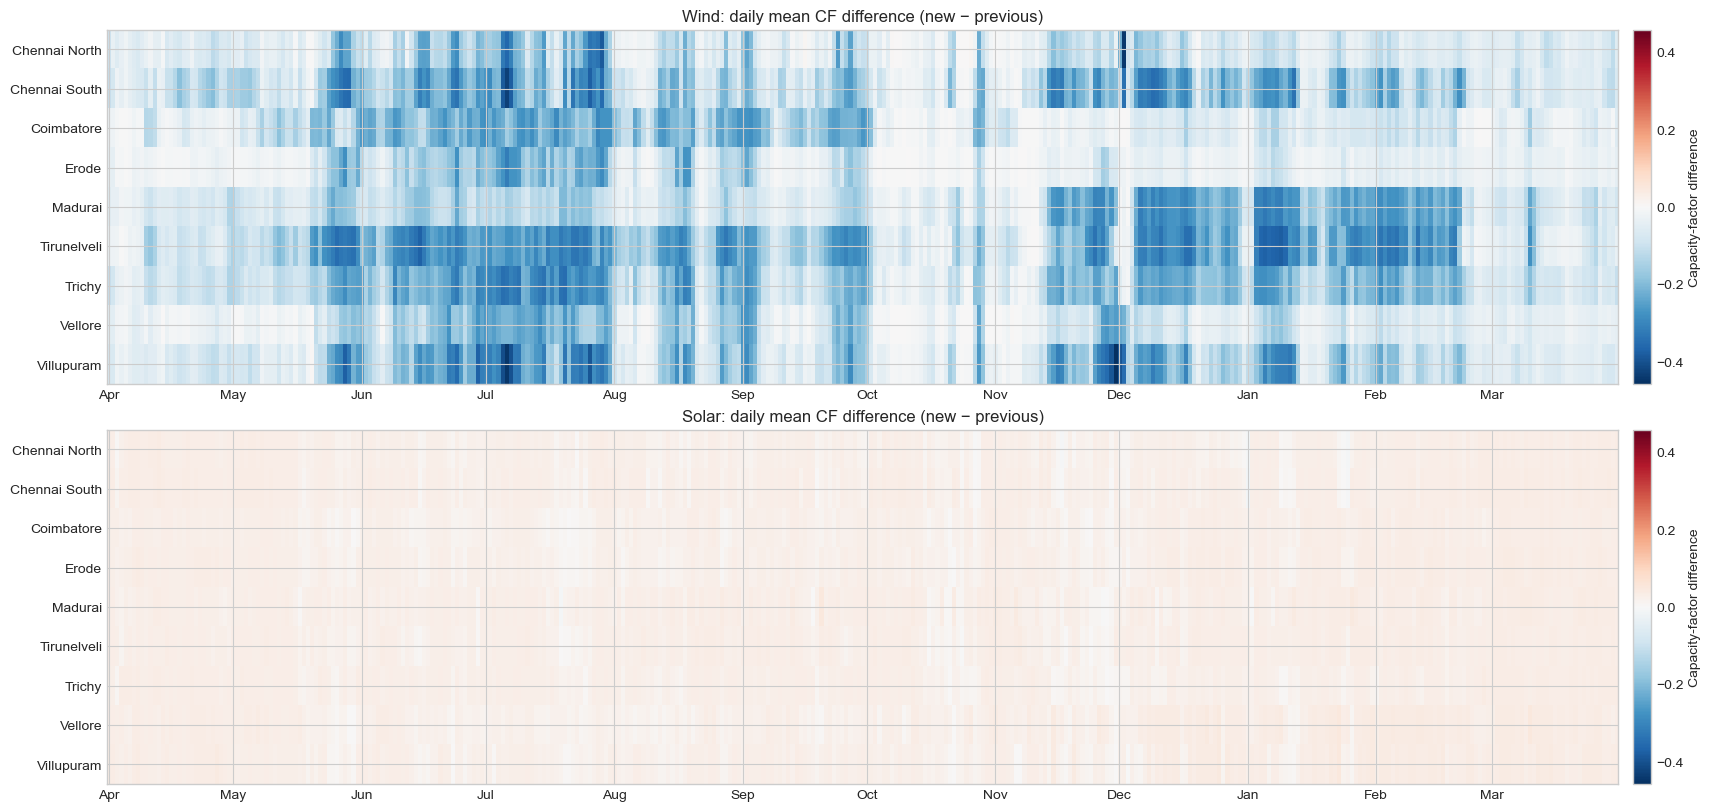

In [6]:
daily = difference.resample('D').mean()
month_starts = pd.date_range(daily.index.min(), daily.index.max(), freq='MS')
daily_limit = daily.abs().to_numpy().max()
fig, axes = plt.subplots(2, 1, figsize=(17, 8), constrained_layout=True)
for axis, technology in zip(axes, TECHNOLOGIES):
    matrix = daily[[f'{area}_{technology}' for area in AREAS]].T.to_numpy()
    image = axis.imshow(matrix, aspect='auto', cmap='RdBu_r', vmin=-daily_limit, vmax=daily_limit)
    axis.set_yticks(np.arange(len(AREAS)), AREA_LABELS)
    tick_positions = [(date - daily.index[0]).days for date in month_starts]
    axis.set_xticks(tick_positions, [date.strftime('%b') for date in month_starts])
    axis.set_title(f'{technology.title()}: daily mean CF difference (new − previous)')
    colorbar = fig.colorbar(image, ax=axis, pad=0.01)
    colorbar.set_label('Capacity-factor difference')
plt.show()


## 4. Capacity-weighted system effect

This uses the renewable capacities currently in `model/generators.csv`; it therefore describes gross available energy under unchanged installed capacity, before dispatch, curtailment, storage, or network constraints.

,Capacity (MW),Previous gross potential (GWh),New active gross potential (GWh),Difference (GWh),Difference (%)
Technology,,,,,
Wind,"12,299.5","31,545.9","15,321.9","-16,224.0",-51.4
Solar,"14,121.5","18,075.5","21,276.7","+3,201.2",+17.7


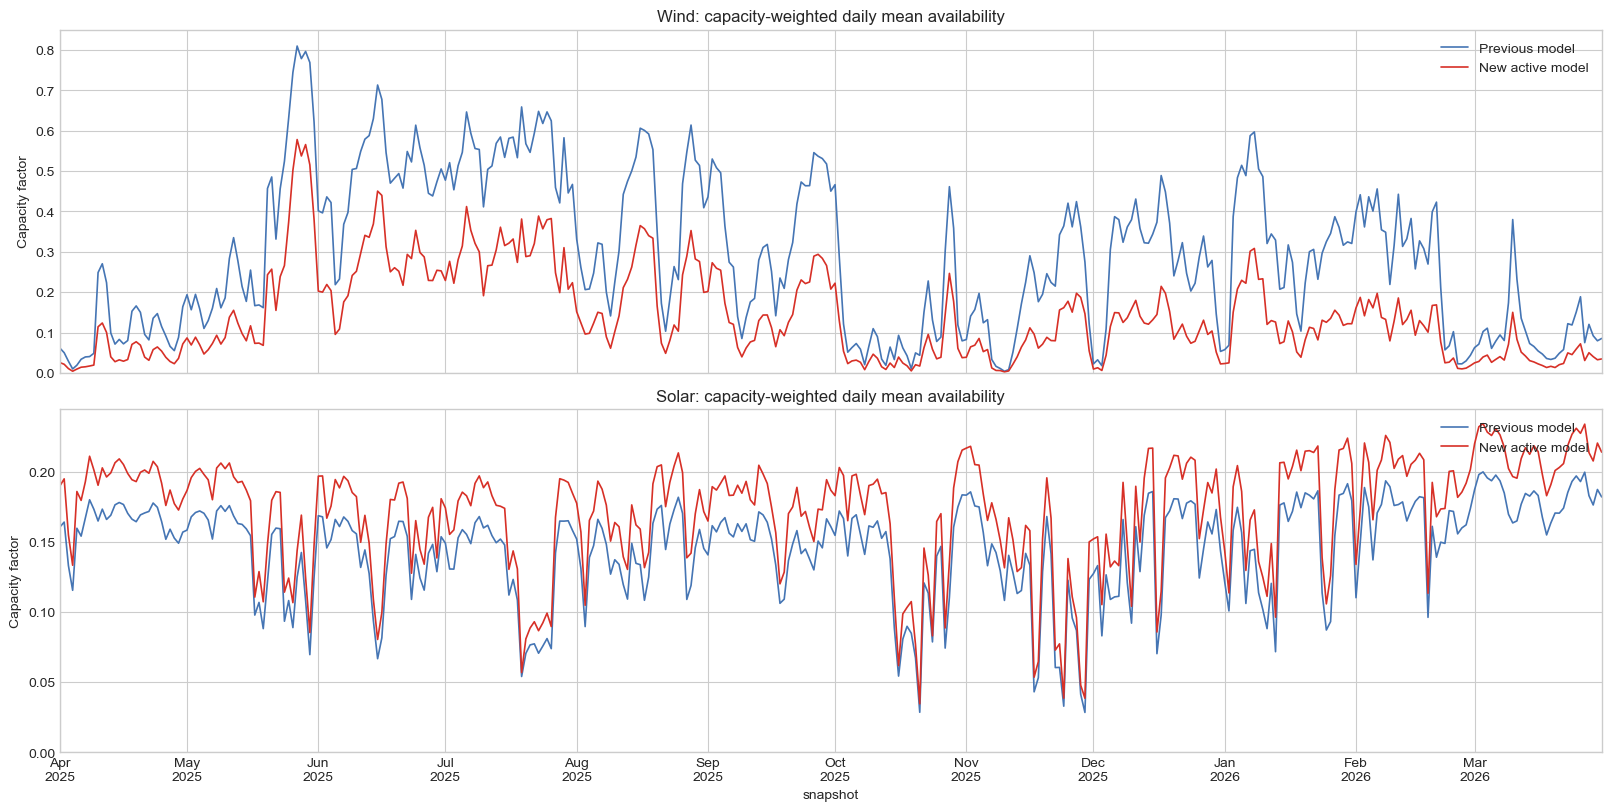

In [7]:
generators = pd.read_csv(GENERATORS)
renewables = generators.loc[generators['carrier'].isin(TECHNOLOGIES)].copy()
renewables['profile'] = (
    renewables['bus'].str.lower().str.replace(' ', '_', regex=False) + '_' + renewables['carrier']
)
capacity_by_profile = renewables.groupby(['carrier', 'profile'])['p_nom'].sum()

fleet_rows = []
fleet_daily = {}
for technology in TECHNOLOGIES:
    capacities = capacity_by_profile.loc[technology]
    capacity_mw = capacities.sum()
    active_mwh = model[capacities.index].mul(capacities, axis=1).sum().sum()
    external_mwh = external[capacities.index].mul(capacities, axis=1).sum().sum()
    fleet_rows.append({
        'Technology': technology.title(),
        'Capacity (MW)': capacity_mw,
        'Previous gross potential (GWh)': active_mwh / 1_000,
        'New active gross potential (GWh)': external_mwh / 1_000,
        'Difference (GWh)': (external_mwh - active_mwh) / 1_000,
        'Difference (%)': 100 * (external_mwh / active_mwh - 1),
    })
    fleet_daily[technology] = pd.DataFrame({
        'Previous model': model[capacities.index].mul(capacities, axis=1).sum(axis=1) / capacity_mw,
        'New active model': external[capacities.index].mul(capacities, axis=1).sum(axis=1) / capacity_mw,
    }).resample('D').mean()

fleet_summary = pd.DataFrame(fleet_rows).set_index('Technology')
display(fleet_summary.style.format({
    'Capacity (MW)': '{:,.1f}', 'Previous gross potential (GWh)': '{:,.1f}',
    'New active gross potential (GWh)': '{:,.1f}', 'Difference (GWh)': '{:+,.1f}',
    'Difference (%)': '{:+.1f}',
}))

fig, axes = plt.subplots(2, 1, figsize=(16, 8), sharex=True, constrained_layout=True)
for axis, technology in zip(axes, TECHNOLOGIES):
    fleet_daily[technology].plot(ax=axis, color=['#4575b4', '#d73027'], linewidth=1.2)
    axis.set_title(f'{technology.title()}: capacity-weighted daily mean availability')
    axis.set_ylabel('Capacity factor')
    axis.set_ylim(bottom=0)
    axis.legend(loc='upper right')
axes[-1].xaxis.set_major_locator(mdates.MonthLocator())
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%b\n%Y'))
plt.show()


## 5. Specific findings

The following text is calculated from the loaded files, so it remains correct when either profile set is updated.

In [8]:
for technology in TECHNOLOGIES:
    subset = annual_summary.loc[technology.title()].copy()
    largest_increase = subset['Mean CF difference'].idxmax()
    largest_decrease = subset['Mean CF difference'].idxmin()
    increase_delta = subset.loc[largest_increase, 'Mean CF difference']
    increase_pct = subset.loc[largest_increase, 'Relative change (%)']
    decrease_delta = subset.loc[largest_decrease, 'Mean CF difference']
    decrease_pct = subset.loc[largest_decrease, 'Relative change (%)']
    display(Markdown(
        f'**{technology.title()}** — highest difference: **{largest_increase}** '
        f'({increase_delta:+.3f} CF; {increase_pct:+.1f}%). '
        f'Lowest difference: **{largest_decrease}** '
        f'({decrease_delta:+.3f} CF; {decrease_pct:+.1f}%).'
    ))

for technology, row in fleet_summary.iterrows():
    difference_gwh = row.at['Difference (GWh)']
    difference_pct = row.at['Difference (%)']
    display(Markdown(
        f'**System {technology.lower()} potential** changes by '
        f'**{difference_gwh:+,.0f} GWh ({difference_pct:+.1f}%)** '
        f'with current model capacity held fixed.'
    ))

display(Markdown(
    '> **Interpretation:** profile differences change availability, not necessarily dispatched energy. '
    'A model run is required to quantify curtailment, storage response, imports, and generation changes.'
))


**Wind** — highest difference: **Erode** (-0.068 CF; -59.8%). Lowest difference: **Tirunelveli** (-0.181 CF; -59.3%).

**Solar** — highest difference: **Madurai** (+0.027 CF; +18.3%). Lowest difference: **Coimbatore** (+0.023 CF; +16.2%).

**System wind potential** changes by **-16,224 GWh (-51.4%)** with current model capacity held fixed.

**System solar potential** changes by **+3,201 GWh (+17.7%)** with current model capacity held fixed.

> **Interpretation:** profile differences change availability, not necessarily dispatched energy. A model run is required to quantify curtailment, storage response, imports, and generation changes.